# Ford Used Car Price Prediction with Generative AI
**Scenario:** a resale car dealer wants a model that predicts the best quotation price for the Ford cars in their lot.

For each task, a prompt was written for a generative AI tool, and the generated Python code was tested and run below.

**Dataset:** Ford Car Pricing (Kaggle, CC0), slightly modified by IBM. Columns: `model`, `year`, `transmission`, `mileage`, `fuelType`, `tax`, `mpg`, `engineSize`, `price` (USD).

## Task 1: Load the data
**Prompt used:**
> Write a Python code that loads the CSV file from this URL into a pandas data frame and shows the first 5 rows: <URL>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMSkillsNetwork-AI0271EN-SkillsNetwork/labs/v1/m3/data/used_car_price_analysis.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(17966, 9)


,model,year,transmission,mileage,fuelType,tax,mpg,engineSize,price
0,Fiesta,2017,Automatic,15944,Petrol,150.0,57.7,1.0,12000
1,Focus,2018,Manual,9083,Petrol,150.0,57.7,1.0,14000
2,Focus,2017,Manual,12456,Petrol,150.0,57.7,1.0,13000
3,Fiesta,2019,Manual,10460,Petrol,145.0,40.3,1.5,17500
4,Fiesta,2019,Automatic,1482,Petrol,145.0,48.7,1.0,16500


## Task 2: Clean the data
**Prompt used:**
> Write a Python code that finds the missing values in each column of the data frame df, replaces the missing values of numeric columns with the column mean, deletes the duplicate rows, and removes rows with an impossible year (later than the newest car in the data, 2020).

In [2]:
print("Missing values per column:")
print(df.isna().sum())

num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# A car "made in 2060" is a data entry error. Kept in, it breaks the polynomial models.
print("Rows with impossible year:")
print(df[df["year"] > 2020])
df = df[df["year"] <= 2020].reset_index(drop=True)
print("\nRows after cleaning:", len(df), "| missing values left:", df.isna().sum().sum())

Missing values per column:
model           0
year            0
transmission    0
mileage         0
fuelType        0
tax             3
mpg             0
engineSize      0
price           0
dtype: int64

Duplicate rows: 154
Rows with impossible year:
         model  year transmission  mileage fuelType    tax   mpg  engineSize  \
17726   Fiesta  2060    Automatic    54807   Petrol  205.0  42.8         1.4   

       price  
17726   6495  

Rows after cleaning: 17811 | missing values left: 0


## Task 3: Number of sales for each fuel type
**Prompt used:**
> Write a Python code that counts the number of cars sold for each fuel type in the data frame df and shows it as a bar chart.

fuelType
Petrol      12080
Diesel       5706
Hybrid         22
Electric        2
Other           1
Name: count, dtype: int64


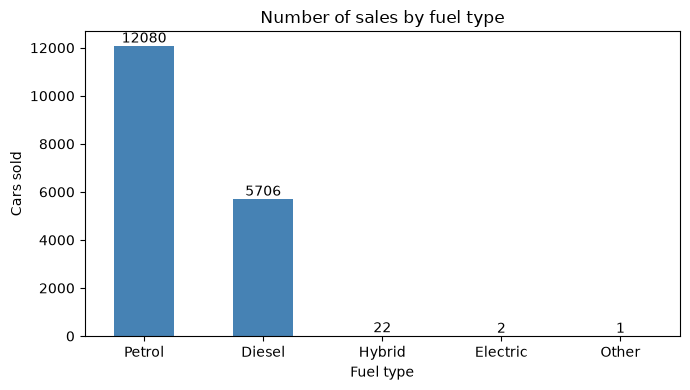

In [3]:
fuel_counts = df["fuelType"].value_counts()
print(fuel_counts)

ax = fuel_counts.plot(kind="bar", color="steelblue", figsize=(7, 4))
ax.bar_label(ax.containers[0])
plt.title("Number of sales by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Cars sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Task 4: Which transmission type has more price outliers
**Prompt used:**
> Write a Python code that creates a box plot of price for each transmission type in the data frame df, and counts the price outliers of each type using the 1.5 x IQR rule.

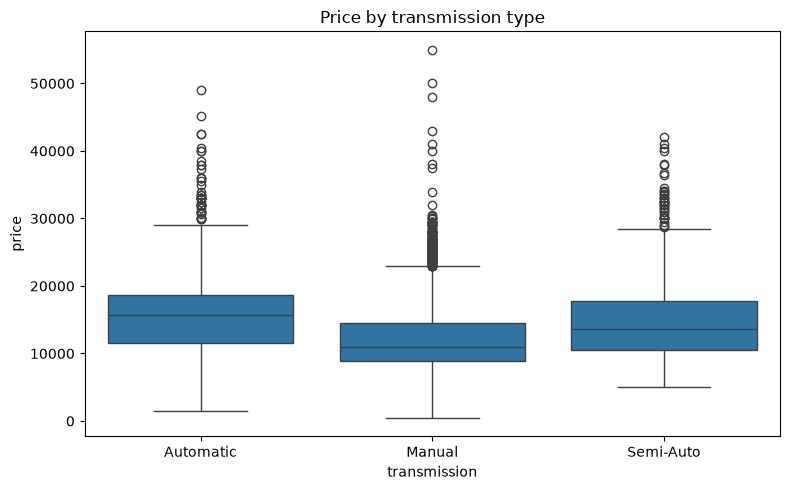

Price outliers per transmission type:
transmission
Manual       193
Automatic     44
Semi-Auto     41
Name: price, dtype: int64


In [4]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="transmission", y="price")
plt.title("Price by transmission type")
plt.tight_layout()
plt.show()


def count_outliers(prices):
    q1, q3 = prices.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((prices < q1 - 1.5 * iqr) | (prices > q3 + 1.5 * iqr)).sum()


print("Price outliers per transmission type:")
print(df.groupby("transmission")["price"].apply(count_outliers).sort_values(ascending=False))

## Task 5: Effect of the features on price
**Prompt used:**
> Write a Python code that shows the correlation of each numeric attribute with price in the data frame df, and a regression plot of mpg vs price.

mileage      -0.530433
mpg          -0.346401
tax           0.406113
engineSize    0.411476
year          0.645236
Name: price, dtype: float64


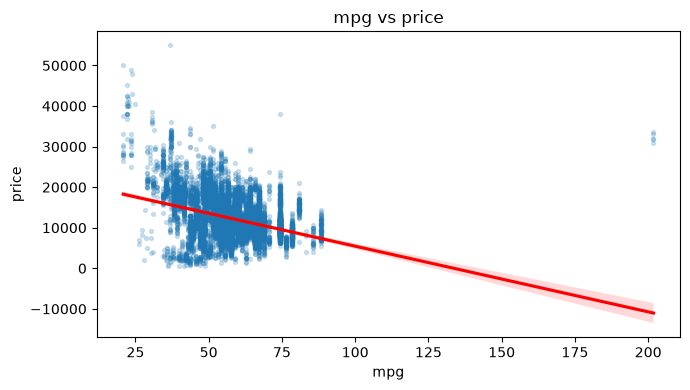

In [5]:
print(df.select_dtypes(include="number").corr()["price"].drop("price").sort_values())

plt.figure(figsize=(7, 4))
sns.regplot(data=df, x="mpg", y="price", scatter_kws={"alpha": 0.2, "s": 8}, line_kws={"color": "red"})
plt.title("mpg vs price")
plt.tight_layout()
plt.show()

## Task 6: Linear regression on a single variable
**Prompt used:**
> Write a Python code that fits a linear regression model to predict price from mpg in the data frame df, and prints the R² and MSE of the model.

In [6]:
X1 = df[["mpg"]]
y = df["price"]
lr1 = LinearRegression().fit(X1, y)
pred = lr1.predict(X1)
results = {}
results["Linear, 1 variable (mpg)"] = (r2_score(y, pred), mean_squared_error(y, pred))
print(f"R²: {results['Linear, 1 variable (mpg)'][0]:.4f} | MSE: {results['Linear, 1 variable (mpg)'][1]:,.0f}")

R²: 0.1200 | MSE: 19,739,005


## Task 7: Linear regression on multiple variables
**Prompt used:**
> Write a Python code that fits a linear regression model to predict price from the variables ["year", "mileage", "tax", "mpg", "engineSize"] in the data frame df, and prints the R² and MSE.

In [7]:
features = ["year", "mileage", "tax", "mpg", "engineSize"]
X = df[features]
lr = LinearRegression().fit(X, y)
pred = lr.predict(X)
results["Linear, multiple variables"] = (r2_score(y, pred), mean_squared_error(y, pred))
print(f"R²: {results['Linear, multiple variables'][0]:.4f} | MSE: {results['Linear, multiple variables'][1]:,.0f}")

R²: 0.7355 | MSE: 5,933,941


## Task 8: Polynomial regression in a pipeline
**Prompt used:**
> Write a Python code that creates a pipeline with StandardScaler, PolynomialFeatures (degree 2) and LinearRegression, fits it on the same multiple variables to predict price, and prints the R² and MSE.

In [8]:
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression()),
])
pipe.fit(X, y)
pred = pipe.predict(X)
results["Polynomial (degree 2), multiple variables"] = (r2_score(y, pred), mean_squared_error(y, pred))
print(f"R²: {results['Polynomial (degree 2), multiple variables'][0]:.4f} | MSE: {results['Polynomial (degree 2), multiple variables'][1]:,.0f}")

R²: 0.7760 | MSE: 5,024,192


## Task 9: Ridge regression on a train/test split
**Prompt used:**
> Write a Python code that splits the data into 80% training and 20% testing (random_state=42), fits a Ridge regression model with alpha=0.1 on the multiple variables, and prints the R² and MSE on the test data.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ridge = Ridge(alpha=0.1).fit(X_train, y_train)
pred = ridge.predict(X_test)
results["Ridge (alpha=0.1), test set"] = (r2_score(y_test, pred), mean_squared_error(y_test, pred))
print(f"Test R²: {results['Ridge (alpha=0.1), test set'][0]:.4f} | Test MSE: {results['Ridge (alpha=0.1), test set'][1]:,.0f}")

Test R²: 0.7435 | Test MSE: 5,896,232


## Task 10: Polynomial + Ridge regression
**Prompt used:**
> Write a Python code that applies a degree 2 polynomial transformation to the training and testing data, fits a Ridge regression model with alpha=0.1 on the transformed training data, and prints the R² and MSE on the test data.

In [10]:
poly = PolynomialFeatures(degree=2, include_bias=False)
scaler = StandardScaler()
X_train_poly = scaler.fit_transform(poly.fit_transform(X_train))
X_test_poly = scaler.transform(poly.transform(X_test))

poly_ridge = Ridge(alpha=0.1).fit(X_train_poly, y_train)
pred = poly_ridge.predict(X_test_poly)
results["Polynomial + Ridge (alpha=0.1), test set"] = (r2_score(y_test, pred), mean_squared_error(y_test, pred))
print(f"Test R²: {results['Polynomial + Ridge (alpha=0.1), test set'][0]:.4f} | Test MSE: {results['Polynomial + Ridge (alpha=0.1), test set'][1]:,.0f}")

Test R²: 0.7590 | Test MSE: 5,539,978


## Task 11: Grid search for the best Ridge alpha
**Prompt used:**
> Write a Python code that uses GridSearchCV with 4-fold cross-validation to find the best alpha for a Ridge regression model, from the values [0.0001, 0.001, 0.01, 0.1, 1, 10], using the degree 2 polynomial training data. Print the best alpha and the R² and MSE of the best model on the test data.

In [11]:
grid = GridSearchCV(Ridge(), {"alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10]}, cv=4, scoring="r2")
grid.fit(X_train_poly, y_train)

best = grid.best_estimator_
pred = best.predict(X_test_poly)
name = f"Polynomial + Ridge, grid search (alpha={grid.best_params_['alpha']}), test set"
results[name] = (r2_score(y_test, pred), mean_squared_error(y_test, pred))
print("Best alpha:", grid.best_params_["alpha"])
print(f"Test R²: {results[name][0]:.4f} | Test MSE: {results[name][1]:,.0f}")

Best alpha: 0.0001
Test R²: 0.7767 | Test MSE: 5,133,062


## Model comparison
Tasks 6–8 are scored on the same data they were trained on, as the project asks. Tasks 9–11 are scored on the 20% test set the models never saw, which is the fairer measure.

In [12]:
summary = pd.DataFrame(results, index=["R²", "MSE"]).T
summary["MSE"] = summary["MSE"].map("{:,.0f}".format)
summary["R²"] = summary["R²"].round(4)
summary

,R²,MSE
"Linear, 1 variable (mpg)",0.1200,"19,739,005"
"Linear, multiple variables",0.7355,"5,933,941"
"Polynomial (degree 2), multiple variables",0.7760,"5,024,192"
"Ridge (alpha=0.1), test set",0.7435,"5,896,232"
"Polynomial + Ridge (alpha=0.1), test set",0.7590,"5,539,978"
"Polynomial + Ridge, grid search (alpha=0.0001), test set",0.7767,"5,133,062"


## Conclusions
**Data cleaning:** 3 missing `tax` values were filled with the mean, 154 duplicate rows were removed, and 1 car with an impossible year (2060) was dropped. That single row was enough to ruin the polynomial models' test scores (R² 0.15 instead of 0.78). Generated code still needs a human to check the data.

**Client requests:**
- **Sales by fuel type:** Petrol 12,081 · Diesel 5,706 · Hybrid 22 · Electric 2 · Other 1. Almost all sales are petrol or diesel.
- **Price outliers:** **Manual** cars have the most (193, vs 44 Automatic and 41 Semi-Auto). Manual is also the most common transmission, so part of this is volume.

**What drives price:** newer cars (`year`, r = 0.64) and bigger engines (r = 0.41) sell for more; more `mileage` (r = −0.53) and higher `mpg` (r = −0.35) go with lower prices. `mpg` alone explains only 12% of price.

**Best model:** degree 2 polynomial + Ridge, with `alpha = 0.0001` from the grid search: **test R² = 0.777**, test RMSE ≈ $2,266. Using several variables matters most (R² 0.12 → 0.74); the polynomial terms add a little more (0.74 → 0.78). The best alpha is almost zero, so regularization barely helps here: the model has few features and many rows, and doesn't overfit.

**Next steps:** add the categorical features (`model`, `transmission`, `fuelType`) with one-hot encoding, which are likely to improve the price quotes the most.